In [2]:
!pip install simpy


  SIMULAÇÃO DE TEORIA DAS FILAS  —  M/M/1  (SimPy)
  Taxa de atendimento μ = 10.0 req/s
  Duração da simulação  = 300 s por cenário
   ρ=λ/μ    λ (req/s)   W simulado (s)    W teórico (s)   Fila média
-----------------------------------------------------------------
    0.10         1.00            0.012            0.111         0.00
    0.30         3.00            0.041            0.143         0.11
    0.50         5.00            0.111            0.200         0.51
    0.70         7.00            0.196            0.333         1.28
    0.80         8.00            0.427            0.500         3.39
    0.90         9.00            1.271            1.000        11.60
    0.95         9.50            1.837            2.000        17.54
    0.97         9.70            4.088            3.333        39.90
    0.99         9.90            2.513           10.000        24.97

→ Observe: conforme ρ → 1 (λ → μ), o tempo de espera W dispara!



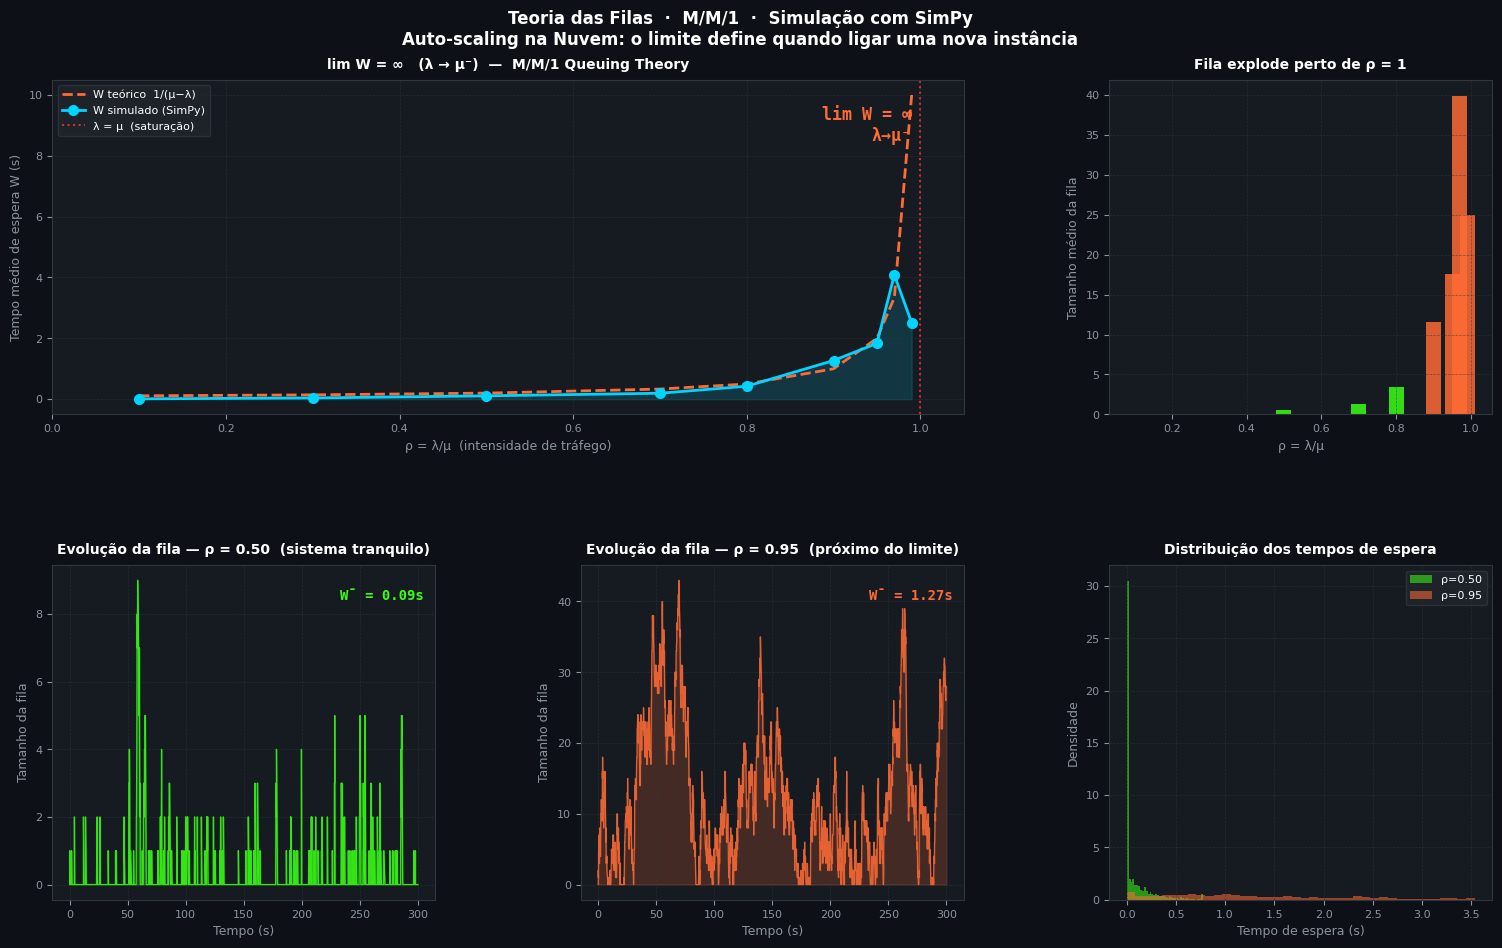

Gráfico salvo em: teoria_das_filas.png


In [4]:
"""
Simulação de Teoria das Filas (Queuing Theory) com SimPy
=========================================================
Baseado no conceito: lim(λ→μ⁻) W = ∞

Quando a taxa de chegada (λ) se aproxima da taxa de atendimento (μ),
o tempo médio de espera na fila (W) tende ao infinito.

Aplicação real: Auto-scaling na nuvem (AWS, Azure, Google Cloud)
"""

import simpy
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from dataclasses import dataclass, field
from typing import List

# ──────────────────────────────────────────────
# Configuração
# ──────────────────────────────────────────────
TAXA_ATENDIMENTO_MU = 10.0   # μ: requisições processadas por segundo
TEMPO_SIMULACAO     = 300    # segundos de simulação por cenário
SEMENTE_ALEATORIA   = 42


@dataclass
class Metricas:
    """Coleta as métricas de cada requisição."""
    tempos_espera:    List[float] = field(default_factory=list)
    tempos_sistema:   List[float] = field(default_factory=list)
    tamanho_fila:     List[float] = field(default_factory=list)
    timestamps:       List[float] = field(default_factory=list)


# ──────────────────────────────────────────────
# Processo SimPy: chegada de requisições
# ──────────────────────────────────────────────
def gerador_requisicoes(env: simpy.Environment,
                        servidor: simpy.Resource,
                        taxa_chegada: float,
                        mu: float,
                        metricas: Metricas):
    """Gera requisições seguindo distribuição de Poisson (exponencial entre chegadas)."""
    req_id = 0
    while True:
        # Intervalo exponencial entre chegadas  →  taxa média = λ req/s
        yield env.timeout(random.expovariate(taxa_chegada))
        req_id += 1
        env.process(processar_requisicao(env, servidor, mu, metricas, req_id))


def processar_requisicao(env: simpy.Environment,
                         servidor: simpy.Resource,
                         mu: float,
                         metricas: Metricas,
                         req_id: int):
    """Processa uma única requisição: entra na fila → é atendida → sai."""
    chegada = env.now
    metricas.tamanho_fila.append(len(servidor.queue))
    metricas.timestamps.append(chegada)

    with servidor.request() as req:
        yield req                            # aguarda o servidor ficar livre
        inicio_atendimento = env.now
        espera = inicio_atendimento - chegada
        metricas.tempos_espera.append(espera)

        # Tempo de serviço exponencial  →  média = 1/μ
        tempo_servico = random.expovariate(mu)
        yield env.timeout(tempo_servico)

        metricas.tempos_sistema.append(env.now - chegada)


# ──────────────────────────────────────────────
# Executar simulação para uma dada carga (λ/μ)
# ──────────────────────────────────────────────
def rodar_simulacao(taxa_chegada: float,
                    mu: float = TAXA_ATENDIMENTO_MU,
                    duracao: int = TEMPO_SIMULACAO,
                    semente: int = SEMENTE_ALEATORIA) -> Metricas:
    random.seed(semente)
    metricas = Metricas()
    env = simpy.Environment()
    servidor = simpy.Resource(env, capacity=1)   # M/M/1
    env.process(gerador_requisicoes(env, servidor, taxa_chegada, mu, metricas))
    env.run(until=duracao)
    return metricas


# ──────────────────────────────────────────────
# Cenários: variando ρ = λ/μ de 0.1 a 0.99
# ──────────────────────────────────────────────
def calcular_w_teorico(lam: float, mu: float) -> float:
    """Fórmula analítica M/M/1: W = 1/(μ - λ)  para λ < μ."""
    if lam >= mu:
        return float('inf')
    return 1.0 / (mu - lam)


# Faixas de carga
cargas_rho = np.array([0.10, 0.30, 0.50, 0.70, 0.80, 0.90, 0.95, 0.97, 0.99])
lambdas    = cargas_rho * TAXA_ATENDIMENTO_MU

print("=" * 65)
print("  SIMULAÇÃO DE TEORIA DAS FILAS  —  M/M/1  (SimPy)")
print("=" * 65)
print(f"  Taxa de atendimento μ = {TAXA_ATENDIMENTO_MU} req/s")
print(f"  Duração da simulação  = {TEMPO_SIMULACAO} s por cenário")
print("=" * 65)
print(f"{'ρ=λ/μ':>8} {'λ (req/s)':>12} {'W simulado (s)':>16} {'W teórico (s)':>16} {'Fila média':>12}")
print("-" * 65)

resultados_simulados  = []
resultados_teoricos   = []
tamanhos_fila_medios  = []

for rho, lam in zip(cargas_rho, lambdas):
    m = rodar_simulacao(lam)
    w_sim  = np.mean(m.tempos_espera)  if m.tempos_espera   else 0.0
    fila_m = np.mean(m.tamanho_fila)   if m.tamanho_fila    else 0.0
    w_teo  = calcular_w_teorico(lam, TAXA_ATENDIMENTO_MU)

    resultados_simulados.append(w_sim)
    resultados_teoricos.append(min(w_teo, 200))   # cap para plotagem
    tamanhos_fila_medios.append(fila_m)

    w_teo_str = f"{w_teo:.3f}" if w_teo < 999 else "→ ∞"
    print(f"{rho:>8.2f} {lam:>12.2f} {w_sim:>16.3f} {w_teo_str:>16} {fila_m:>12.2f}")

print("=" * 65)
print("\n→ Observe: conforme ρ → 1 (λ → μ), o tempo de espera W dispara!\n")


# ──────────────────────────────────────────────
# Simulação detalhada: comparar ρ=0.5 vs ρ=0.95
# ──────────────────────────────────────────────
cenarios_destaque = {
    "ρ = 0.50  (sistema tranquilo)": 0.50 * TAXA_ATENDIMENTO_MU,
    "ρ = 0.95  (próximo do limite)": 0.95 * TAXA_ATENDIMENTO_MU,
}

dados_destaque = {}
for nome, lam in cenarios_destaque.items():
    dados_destaque[nome] = rodar_simulacao(lam, semente=7)


# ──────────────────────────────────────────────
# Gráficos
# ──────────────────────────────────────────────
plt.style.use("dark_background")
fig = plt.figure(figsize=(16, 10), facecolor="#0d1117")
gs  = gridspec.GridSpec(2, 3, figure=fig,
                        hspace=0.45, wspace=0.38,
                        left=0.07, right=0.97, top=0.90, bottom=0.08)

COR_AZUL    = "#00d4ff"
COR_LARANJA = "#ff6b35"
COR_VERDE   = "#39ff14"
COR_FUNDO   = "#161b22"
COR_GRADE   = "#30363d"


def estilizar_eixo(ax, titulo):
    ax.set_facecolor(COR_FUNDO)
    ax.set_title(titulo, color="white", fontsize=10, fontweight="bold", pad=8)
    ax.tick_params(colors="#8b949e", labelsize=8)
    ax.spines[:].set_color(COR_GRADE)
    ax.grid(True, color=COR_GRADE, linewidth=0.5, linestyle="--", alpha=0.6)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_color("#8b949e")


# ── Gráfico 1: W simulado vs teórico ──────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(cargas_rho, resultados_teoricos, "--", color=COR_LARANJA,
         linewidth=2, label="W teórico  1/(μ−λ)", zorder=3)
ax1.plot(cargas_rho, resultados_simulados, "o-", color=COR_AZUL,
         linewidth=2, markersize=7, label="W simulado (SimPy)", zorder=4)
ax1.axvline(x=1.0, color="#ff3333", linestyle=":", linewidth=1.5,
            label="λ = μ  (saturação)", alpha=0.8)
ax1.fill_between(cargas_rho, resultados_simulados, alpha=0.15, color=COR_AZUL)
ax1.set_xlabel("ρ = λ/μ  (intensidade de tráfego)", color="#8b949e", fontsize=9)
ax1.set_ylabel("Tempo médio de espera W (s)", color="#8b949e", fontsize=9)
ax1.set_xlim(0, 1.05)
estilizar_eixo(ax1, "lim W = ∞   (λ → μ⁻)  —  M/M/1 Queuing Theory")
leg = ax1.legend(fontsize=8, facecolor="#21262d", edgecolor=COR_GRADE,
                 labelcolor="white")

# anotação da fórmula
ax1.annotate("lim W = ∞\nλ→μ⁻",
             xy=(0.99, max(resultados_teoricos) * 0.85),
             fontsize=12, color=COR_LARANJA, ha="right",
             fontfamily="monospace", fontweight="bold")


# ── Gráfico 2: Tamanho médio da fila ──────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
bars = ax2.bar(cargas_rho, tamanhos_fila_medios, width=0.04,
               color=[COR_VERDE if r < 0.90 else COR_LARANJA
                      for r in cargas_rho], alpha=0.85)
ax2.set_xlabel("ρ = λ/μ", color="#8b949e", fontsize=9)
ax2.set_ylabel("Tamanho médio da fila", color="#8b949e", fontsize=9)
estilizar_eixo(ax2, "Fila explode perto de ρ = 1")


# ── Gráficos 3 & 4: Evolução temporal dos dois cenários ───────
cores_cenario = [COR_VERDE, COR_LARANJA]
nomes_curtos  = ["ρ=0.50", "ρ=0.95"]

for i, (nome, dados) in enumerate(dados_destaque.items()):
    ax = fig.add_subplot(gs[1, i])
    if dados.timestamps and dados.tamanho_fila:
        ax.plot(dados.timestamps, dados.tamanho_fila,
                color=cores_cenario[i], linewidth=0.9, alpha=0.85)
        ax.fill_between(dados.timestamps, dados.tamanho_fila,
                        alpha=0.2, color=cores_cenario[i])
    ax.set_xlabel("Tempo (s)", color="#8b949e", fontsize=9)
    ax.set_ylabel("Tamanho da fila", color="#8b949e", fontsize=9)
    estilizar_eixo(ax, f"Evolução da fila — {nome}")

    w_medio = np.mean(dados.tempos_espera) if dados.tempos_espera else 0
    ax.text(0.97, 0.93, f"W̄ = {w_medio:.2f}s",
            transform=ax.transAxes, ha="right", va="top",
            color=cores_cenario[i], fontsize=10, fontweight="bold",
            fontfamily="monospace")


# ── Gráfico 5: Distribuição dos tempos de espera ──────────────
ax5 = fig.add_subplot(gs[1, 2])
for i, (nome, dados) in enumerate(dados_destaque.items()):
    if dados.tempos_espera:
        esperas = np.array(dados.tempos_espera)
        esperas_clip = np.clip(esperas, 0, np.percentile(esperas, 99))
        ax5.hist(esperas_clip, bins=40, density=True,
                 alpha=0.55, color=cores_cenario[i],
                 label=nomes_curtos[i], edgecolor="none")
ax5.set_xlabel("Tempo de espera (s)", color="#8b949e", fontsize=9)
ax5.set_ylabel("Densidade", color="#8b949e", fontsize=9)
estilizar_eixo(ax5, "Distribuição dos tempos de espera")
leg5 = ax5.legend(fontsize=8, facecolor="#21262d",
                  edgecolor=COR_GRADE, labelcolor="white")


# Título global
fig.suptitle(
    "Teoria das Filas  ·  M/M/1  ·  Simulação com SimPy\n"
    "Auto-scaling na Nuvem: o limite define quando ligar uma nova instância",
    color="white", fontsize=12, fontweight="bold", y=0.97
)

plt.savefig("teoria_das_filas.png", dpi=150, bbox_inches="tight", facecolor="#0d1117")
plt.show()
print("Gráfico salvo em: teoria_das_filas.png")
